In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.manifold import TSNE

In [31]:
wine = load_wine(as_frame=True)
X = wine.data              # 178 x 13 feature table
y = wine.target            # used ONLY for colouring plots

print(X.shape)
print(X.var().sort_values())

(178, 13)
nonflavanoid_phenols                0.015489
hue                                 0.052245
ash                                 0.075265
proanthocyanins                     0.327595
total_phenols                       0.391690
od280/od315_of_diluted_wines        0.504086
alcohol                             0.659062
flavanoids                          0.997719
malic_acid                          1.248015
color_intensity                     5.374449
alcalinity_of_ash                  11.152686
magnesium                         203.989335
proline                         99166.717355
dtype: float64


In [32]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Means:")
print(X_scaled.mean(axis=0))

print("Standard deviations:")
print(X_scaled.std(axis=0))

Means:
[-8.38280756e-16 -1.19754394e-16 -8.37033314e-16 -3.99181312e-17
 -3.99181312e-17  0.00000000e+00 -3.99181312e-16  3.59263181e-16
 -1.19754394e-16  2.49488320e-17  1.99590656e-16  3.19345050e-16
 -1.59672525e-16]
Standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Task 4 — PCA on Unscaled vs Scaled Data

In [33]:
pca_unscaled = PCA()
pca_unscaled.fit(X)

pca_scaled = PCA()
pca_scaled.fit(X_scaled)

print("Unscaled PVE:")
print(pca_unscaled.explained_variance_ratio_)

print("\nScaled PVE:")
print(pca_scaled.explained_variance_ratio_)

Unscaled PVE:
[9.98091230e-01 1.73591562e-03 9.49589576e-05 5.02173562e-05
 1.23636847e-05 8.46213034e-06 2.80681456e-06 1.52308053e-06
 1.12783044e-06 7.21415811e-07 3.78060267e-07 2.12013755e-07
 8.25392788e-08]

Scaled PVE:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]


In [34]:
print("Unscaled PC1 PVE:", pca_unscaled.explained_variance_ratio_[0])
print("Unscaled PC2 PVE:", pca_unscaled.explained_variance_ratio_[1])

print("Scaled PC1 PVE:", pca_scaled.explained_variance_ratio_[0])
print("Scaled PC2 PVE:", pca_scaled.explained_variance_ratio_[1])

Unscaled PC1 PVE: 0.9980912304918974
Unscaled PC2 PVE: 0.0017359156247057502
Scaled PC1 PVE: 0.3619884809992633
Scaled PC2 PVE: 0.1920749025700894


In [35]:
loadings_unscaled = pd.Series(
    pca_unscaled.components_[0],
    index=X.columns
)

print(loadings_unscaled)

alcohol                         0.001659
malic_acid                     -0.000681
ash                             0.000195
alcalinity_of_ash              -0.004671
magnesium                       0.017868
total_phenols                   0.000990
flavanoids                      0.001567
nonflavanoid_phenols           -0.000123
proanthocyanins                 0.000601
color_intensity                 0.002327
hue                             0.000171
od280/od315_of_diluted_wines    0.000705
proline                         0.999823
dtype: float64


Task 5 — Scree Plot and Cumulative PVE

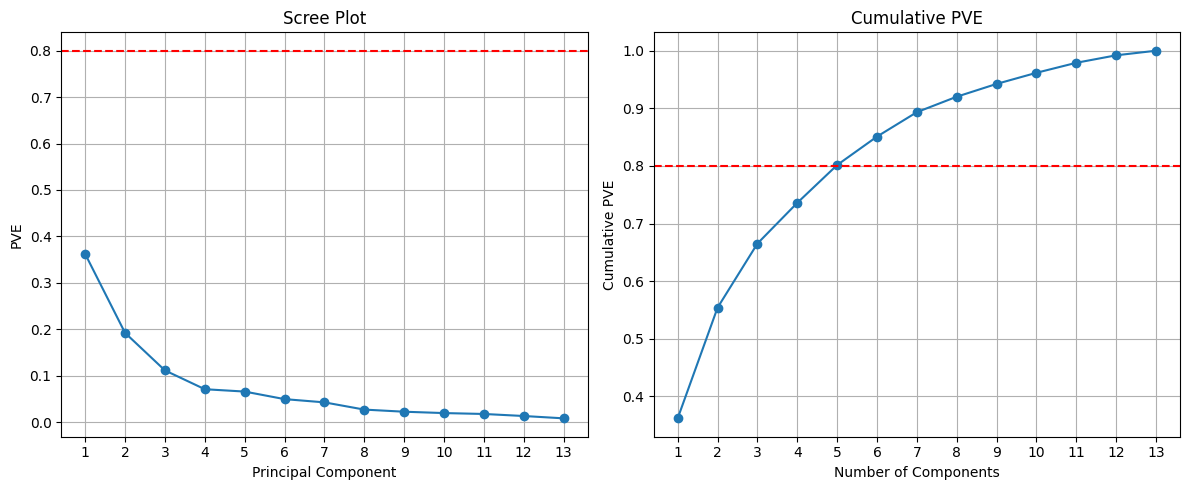

In [36]:
pca = PCA()
pca.fit(X_scaled)

pve = pca.explained_variance_ratio_
cum_pve = np.cumsum(pve)
components = np.arange(1, len(pve) + 1)

# Create two plots side by side
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Left: Scree Plot
ax[0].plot(components, pve, marker='o')
ax[0].axhline(0.80, linestyle='--', color='red')
ax[0].set_title("Scree Plot")
ax[0].set_xlabel("Principal Component")
ax[0].set_ylabel("PVE")
ax[0].set_xticks(components)
ax[0].grid(True)

# Right: Cumulative PVE
ax[1].plot(components, cum_pve, marker='o')
ax[1].axhline(0.80, linestyle='--', color='red')
ax[1].set_title("Cumulative PVE")
ax[1].set_xlabel("Number of Components")
ax[1].set_ylabel("Cumulative PVE")
ax[1].set_xticks(components)
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [37]:
for i, value in enumerate(cum_pve, start=1):
    print(i, value)

1 0.3619884809992633
2 0.5540633835693527
3 0.6652996889318524
4 0.7359899907589927
5 0.8016229275554787
6 0.8509811607477045
7 0.8933679539739376
8 0.9201754434577263
9 0.9423969775056233
10 0.9616971684450641
11 0.9790655253449633
12 0.9920478511010055
13 1.0


Task 6: Interpret the Loadings

In [38]:
loadings = pd.DataFrame(
    pca_scaled.components_[:3].T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3"]
)

print(loadings)

                                   PC1       PC2       PC3
alcohol                       0.144329  0.483652 -0.207383
malic_acid                   -0.245188  0.224931  0.089013
ash                          -0.002051  0.316069  0.626224
alcalinity_of_ash            -0.239320 -0.010591  0.612080
magnesium                     0.141992  0.299634  0.130757
total_phenols                 0.394661  0.065040  0.146179
flavanoids                    0.422934 -0.003360  0.150682
nonflavanoid_phenols         -0.298533  0.028779  0.170368
proanthocyanins               0.313429  0.039302  0.149454
color_intensity              -0.088617  0.529996 -0.137306
hue                           0.296715 -0.279235  0.085222
od280/od315_of_diluted_wines  0.376167 -0.164496  0.166005
proline                       0.286752  0.364903 -0.126746


In [39]:
print("PC1:")
print(loadings["PC1"].abs().nlargest(3))

print("\nPC2:")
print(loadings["PC2"].abs().nlargest(3))

PC1:
flavanoids                      0.422934
total_phenols                   0.394661
od280/od315_of_diluted_wines    0.376167
Name: PC1, dtype: float64

PC2:
color_intensity    0.529996
alcohol            0.483652
proline            0.364903
Name: PC2, dtype: float64


Task 7: Visualize the Scores

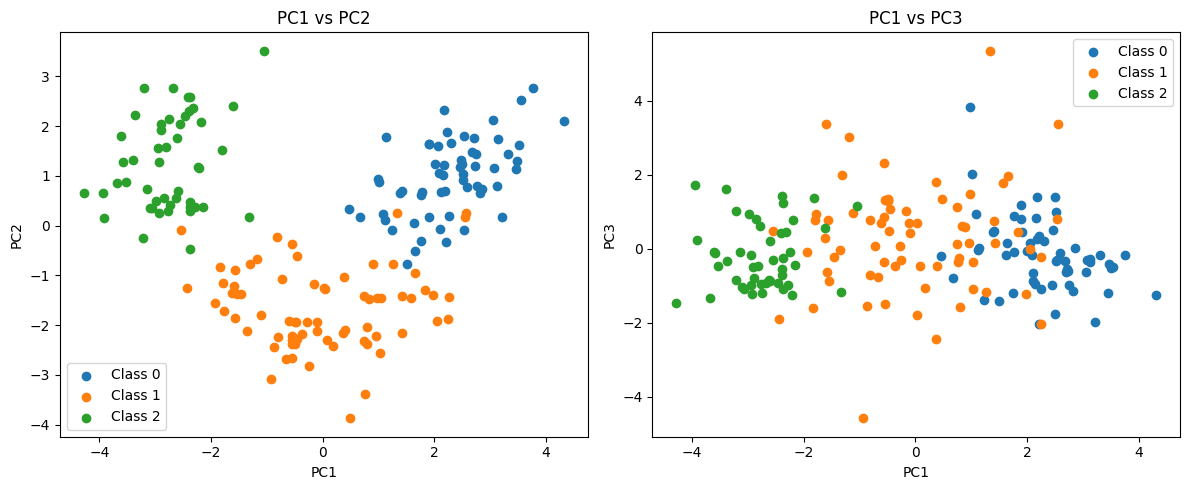

In [40]:
scores = pca_scaled.transform(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for cls in np.unique(y):
    ax[0].scatter(
        scores[y == cls, 0],
        scores[y == cls, 1],
        label=f"Class {cls}"
    )

    ax[1].scatter(
        scores[y == cls, 0],
        scores[y == cls, 2],
        label=f"Class {cls}"
    )

ax[0].set_title("PC1 vs PC2")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")
ax[0].legend()

ax[1].set_title("PC1 vs PC3")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC3")
ax[1].legend()

plt.tight_layout()
plt.show()

Task 8: Reconstruct from m Components

In [41]:
for m in [2, 5, 8, 13]:
    pca_m = PCA(n_components=m)

    scores_m = pca_m.fit_transform(X_scaled)
    X_reconstructed = pca_m.inverse_transform(scores_m)

    cumulative_pve = pca_m.explained_variance_ratio_.sum()

    error = np.mean((X_scaled - X_reconstructed) ** 2)

    print(f"m = {m}")
    print(f"Cumulative PVE = {cumulative_pve:.4f}")
    print(f"Reconstruction Error = {error:.4f}")
    print()

m = 2
Cumulative PVE = 0.5541
Reconstruction Error = 0.4459

m = 5
Cumulative PVE = 0.8016
Reconstruction Error = 0.1984

m = 8
Cumulative PVE = 0.9202
Reconstruction Error = 0.0798

m = 13
Cumulative PVE = 1.0000
Reconstruction Error = 0.0000



PART C — ANOMALY DETECTION

Step 1 — Create the dataset with 8 anomalies

In [42]:
rng = np.random.RandomState(42)
n = len(X_scaled)

idx = rng.choice(n, 8, replace=False)
A = X_scaled[idx].copy()

for i in range(8):
    cols = rng.choice(13, 4, replace=False)
    A[i, cols] += rng.choice([-1, 1], 4) * rng.uniform(3, 5, 4)

X_all = np.vstack([X_scaled, A])
is_anom = np.r_[np.zeros(n, bool), np.ones(8, bool)]

def report(name, flagged):
    caught = int(flagged[is_anom].sum())
    false_alarms = int(flagged[~is_anom].sum())
    print(f"{name}: flagged={int(flagged.sum())} caught={caught}/8 false alarms={false_alarms}")

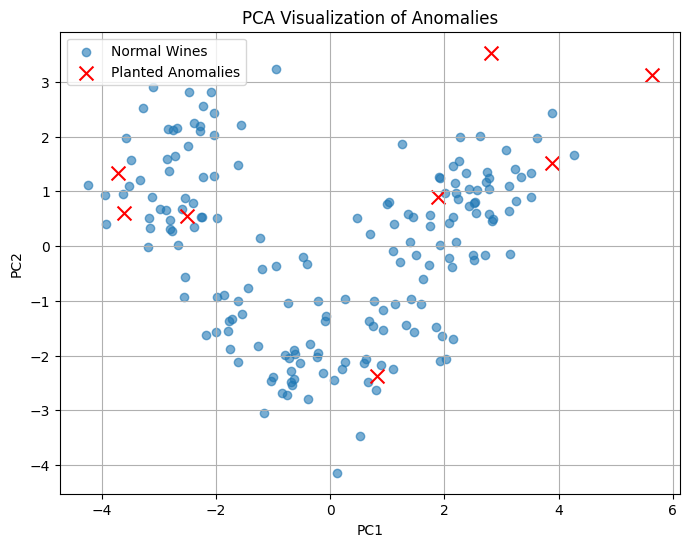

In [43]:
pca_anom = PCA(n_components=2)
scores_all = pca_anom.fit_transform(X_all)

plt.figure(figsize=(8, 6))

plt.scatter(
    scores_all[~is_anom, 0],
    scores_all[~is_anom, 1],
    label="Normal Wines",
    alpha=0.6
)

plt.scatter(
    scores_all[is_anom, 0],
    scores_all[is_anom, 1],
    color="red",
    marker="x",
    s=100,
    label="Planted Anomalies"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization of Anomalies")
plt.legend()
plt.grid(True)
plt.show()

Part 2 — Scikit-learn Python code

In [44]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

iso.fit(X_all)

flag_if = iso.predict(X_all) == -1

report("Isolation Forest", flag_if)

Isolation Forest: flagged=10 caught=8/8 false alarms=2


In [45]:
from sklearn.neighbors import LocalOutlierFactor

for k in [5, 20, 40]:
    lof = LocalOutlierFactor(
        n_neighbors=k,
        contamination=0.05
    )

    flag = lof.fit_predict(X_all) == -1

    report(f"LOF k={k}", flag)

LOF k=5: flagged=10 caught=8/8 false alarms=2
LOF k=20: flagged=10 caught=8/8 false alarms=2
LOF k=40: flagged=10 caught=8/8 false alarms=2


In [46]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

flag_lof = lof.fit_predict(X_all) == -1

Task 12: Compare Detectors and Investigate a False Alarm

In [47]:
both = flag_if & flag_lof
only_if = flag_if & ~flag_lof
only_lof = ~flag_if & flag_lof

print("Flagged by both:", both.sum())
print("Only Isolation Forest:", only_if.sum())
print("Only LOF:", only_lof.sum())

Flagged by both: 9
Only Isolation Forest: 1
Only LOF: 1


In [48]:
false_alarm_mask = flag_if & ~is_anom

false_alarm_df = pd.DataFrame(
    X_all[false_alarm_mask],
    columns=X.columns,
    index=np.where(false_alarm_mask)[0]
)

print(false_alarm_df)

      alcohol  malic_acid       ash  alcalinity_of_ash  magnesium  \
121 -1.779545   -0.257044  3.156325           2.704083   1.352198   
158  1.654492   -0.589180  1.218995           1.653086  -0.122282   

     total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
121       1.417883    3.062832              0.871420         0.489009   
158       0.808997   -0.722123              1.354888         1.943238   

     color_intensity       hue  od280/od315_of_diluted_wines   proline  
121         0.407442 -0.120430                      1.523058 -0.897687  
158         3.435432 -1.699872                     -0.920468 -0.276711  


In [49]:
for index, row in false_alarm_df.iterrows():
    print("\nObservation:", index)
    print(row.abs().sort_values(ascending=False).head(3))


Observation: 121
ash                  3.156325
flavanoids           3.062832
alcalinity_of_ash    2.704083
Name: 121, dtype: float64

Observation: 158
color_intensity    3.435432
proanthocyanins    1.943238
hue                1.699872
Name: 158, dtype: float64


Task 13: t-SNE and the Effect of Perplexity

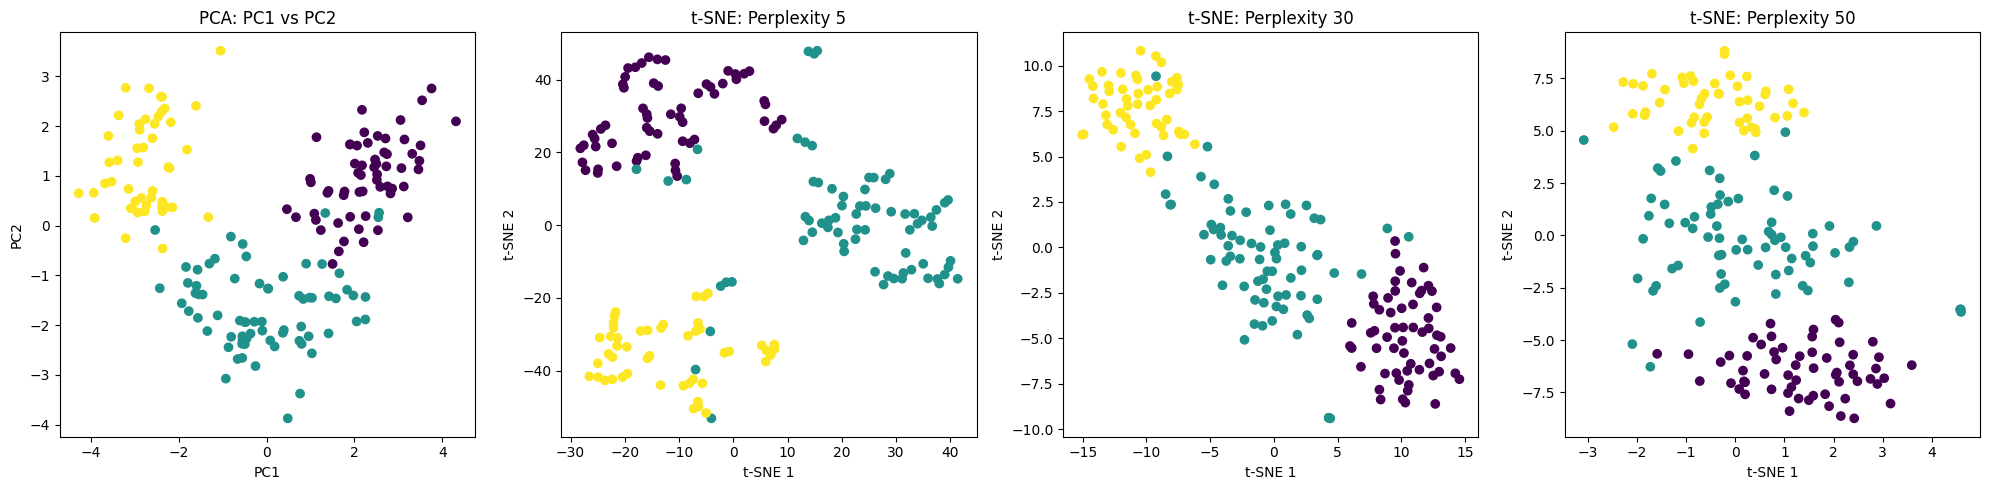

In [50]:
from sklearn.manifold import TSNE

embeddings = {}

for perp in [5, 30, 50]:
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        random_state=42,
        init='pca'
    )
    embeddings[perp] = tsne.fit_transform(X_scaled)

# PCA scores
pca_scores = pca_scaled.transform(X_scaled)

fig, ax = plt.subplots(1, 4, figsize=(20, 5))

# PCA plot
ax[0].scatter(
    pca_scores[:, 0],
    pca_scores[:, 1],
    c=y,
    cmap='viridis'
)
ax[0].set_title("PCA: PC1 vs PC2")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# t-SNE plots
for i, perp in enumerate([5, 30, 50]):
    ax[i+1].scatter(
        embeddings[perp][:, 0],
        embeddings[perp][:, 1],
        c=y,
        cmap='viridis'
    )
    ax[i+1].set_title(f"t-SNE: Perplexity {perp}")
    ax[i+1].set_xlabel("t-SNE 1")
    ax[i+1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

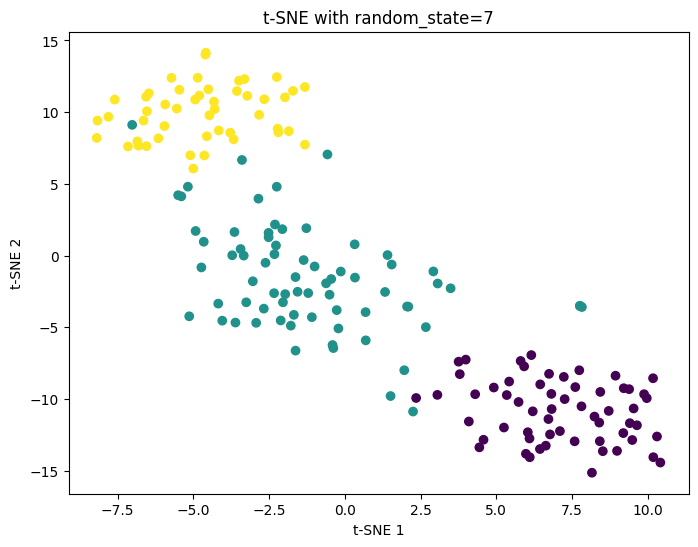

In [51]:
tsne_7 = TSNE(
    n_components=2,
    perplexity=30,
    random_state=7,
    init='pca'
)

embedding_7 = tsne_7.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    embedding_7[:, 0],
    embedding_7[:, 1],
    c=y,
    cmap='viridis'
)

plt.title("t-SNE with random_state=7")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()